Datenerhebung
Die Rohdaten werden mit einem Python-Skript von Dexscreener abgerufen und in einer CSV-Datei gespeichert.

Verwendete Technologien: asyncio, curl_cffi, BeautifulSoup und pandas.

Erfasste Merkmale: Token-Name und -Adresse, Pair-Adresse, Blockchain, DEX, Erstellungszeitpunkt des Pools, Preis, Liquidität, Marktkapitalisierung, FDV, Preisänderungen sowie Kauf-, Verkaufs- und Volumenstatistiken.
Auswahl der Token auf Dexscreener

Es werden nicht wahllos alle verfügbaren Token gesammelt. Bereits die Dexscreener-Seite, von der der Collector die Daten abruft, ist durch folgende Filter eingeschränkt:
- Alter des Pools: höchstens etwa 24–48 Stunden. Ziel ist es, neu gelistete beziehungsweise neu gehandelte Token zu untersuchen und ältere Projekte aus der Auswahl auszuschließen.
- Handelsvolumen der letzten Stunde (Volume 1h): über 1000 USD. Damit werden Pools mit erkennbarer jüngster Handelsaktivität für die Analyse ausgewählt. Ein vorhandenes Handelsvolumen beweist jedoch nicht, dass keine Bots oder künstliche Handelsaktivität beteiligt sind.
- Liquidität: über 500 USD. Damit sollen Pools mit sehr geringer Liquidität ausgeschlossen werden.
Diese Filter sollen die Auswahl auf junge Pools mit einer gewissen Mindestaktivität und Liquidität eingrenzen.

Der Collector prüft die bereits gespeicherten pair_address-Werte, um dieselben Handelspaare nicht erneut hinzuzufügen. Die spätere Analyse betrachtet pro Token nur einen repräsentativen Pool: den Pool mit der höchsten Liquidität innerhalb des geladenen Datensatzes. Damit sollen mehrfach vorkommende Token über verschiedene Handelspaare hinweg nicht übergewichtet werden. Das ist eine bewusste Auswahlentscheidung und keine Garantie, dass dieser Pool auf dem gesamten Markt immer der wichtigste ist.

Daten laden und erste Inspektion
Zunächst werden die benötigten Bibliotheken importiert und der Datensatz aus der CSV-Datei geladen. Anschließend prüfe ich die ersten Zeilen, die Datentypen, die Anzahl der Einträge und fehlende Werte. Diese erste Inspektion hilft dabei, mögliche Datenqualitätsprobleme vor der Analyse zu erkennen.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('crypto.csv')

In [3]:
df.head()

,name,token_address,pair_address,chain,dex_name,pool_created_at,price_usd,liquidity_usd,market_cap,fdv,...,txns_6h,buys_6h,sells_6h,volume_6h,price_change_24h,txns_24h,buys_24h,sells_24h,volume_24h,is_socials
0,Pondering Deer,5B8qahEJezLtTHPU1Du1AsfAMf4kUVAdaMky7vhjpump,4btVoSm4PaW3w5yXdCfQRvHhgkkYni1orgTfN1CpjbxH,solana,pumpswap,1782476143000,0.000091,24999.02,91314.0,91314.0,...,21585,15626,5959,600416.68,-52.88,82299,60948,21351,3192098.07,True
1,TRADER,BbydPty2qDLNjoeHtWiFjBfibBvBkXK84agHuU2rpump,5LSTGoUgA7ghhDBgWG1Ego2Eq839x5yZUDqoXxsPztwz,solana,pumpswap,1782533146000,0.001044,98241.91,1043997.0,1043997.0,...,45113,24485,20628,6913807.26,2825.00,65058,36747,28311,8962444.80,True
2,Buy Until The Top,y4XpRmq8vCBKasQJy447SR1NEtXFpVQV8o4T7ZPpump,EyKXDqdb8DgnfvBcSGcRYT7hQAp77ExUHHBPJMRPMVPC,solana,pumpswap,1782533710000,0.000115,27323.74,114886.0,114886.0,...,23560,12717,10843,1000574.84,112.00,55190,31029,24161,2178240.02,True
3,PokéBomber,8j9CPCFFXHpHARjEqyNNe6diPkBoebqGP3a38aXfpump,6X4rAdb4x4EygTLchzGUfVkFjyk34BGFhqhmkYU3eK64,solana,pumpswap,1782546693000,0.000341,44958.31,341491.0,341491.0,...,38380,25436,12944,1168178.96,441.00,38380,25436,12944,1168178.96,True
4,Hodly,6oPG5q5SPNtQTxeu8RRWvh6mngsauznC2SVVtXqPpump,HETLzRHxiJZQu5s79HucxXQLRHtujE4qu6kDcaUAbVEu,solana,pumpswap,1782483787000,0.000409,47683.08,409339.0,409339.0,...,5474,2896,2578,157007.78,1273.00,20157,11723,8434,894542.18,True


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 16075 entries, 0 to 16074
Data columns (total 26 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   name              16073 non-null  str    
 1   token_address     16075 non-null  str    
 2   pair_address      16075 non-null  str    
 3   chain             16075 non-null  str    
 4   dex_name          16075 non-null  str    
 5   pool_created_at   16075 non-null  int64  
 6   price_usd         16075 non-null  float64
 7   liquidity_usd     16073 non-null  float64
 8   market_cap        15643 non-null  float64
 9   fdv               15643 non-null  float64
 10  price_change_1h   14939 non-null  float64
 11  txns_1h           16075 non-null  int64  
 12  buys_1h           16075 non-null  int64  
 13  sells_1h          16075 non-null  int64  
 14  volume_1h         16075 non-null  float64
 15  price_change_6h   15165 non-null  float64
 16  txns_6h           16075 non-null  int64  
 17  buys

In [5]:
df[df['token_address'].duplicated()]

,name,token_address,pair_address,chain,dex_name,pool_created_at,price_usd,liquidity_usd,market_cap,fdv,...,txns_6h,buys_6h,sells_6h,volume_6h,price_change_24h,txns_24h,buys_24h,sells_24h,volume_24h,is_socials
1253,The Black Bull,9cRCn9rGT8V2imeM2BaKs13yhMEais3ruM3rPvTGpump,6e7V9eegCHw997T72MxgwwJipZ6GJyZF8NvjkzT1rvpN,solana,meteora,1782628736000,0.094350,396402.01,94356269.0,94356269.0,...,15238,8040,7198,5859425.04,144.00,28947,15056,13891,10453262.96,True
1254,The Black Bull,9cRCn9rGT8V2imeM2BaKs13yhMEais3ruM3rPvTGpump,BetLT47eFXDZnjM1cmZhQ4oNJkYaPZYH5yv6atfPfAri,solana,meteora,1782632966000,0.094110,65522.04,94112950.0,94112950.0,...,10015,4795,5220,863938.93,54.64,15281,7376,7905,1100477.30,True
1257,The Black Bull,9cRCn9rGT8V2imeM2BaKs13yhMEais3ruM3rPvTGpump,74UCGDNEXVH26DWfswmFbVDZA7VG9Dp7yYP2CG4F76DN,solana,raydium,1782626890000,0.095130,45523.16,95134080.0,95134080.0,...,5198,2497,2701,294426.47,308.00,12509,5855,6654,384679.33,True
1258,The Black Bull,9cRCn9rGT8V2imeM2BaKs13yhMEais3ruM3rPvTGpump,AUvX4hEMi9t43aqovA5tEAA5AZ7yugcpHa8SkJVEoEKa,solana,meteora,1782569788000,0.093110,271456.71,93110978.0,93110978.0,...,757,394,363,162673.81,1762.00,4793,2679,2114,1346812.20,True
1260,WYNN,G9ds9rppyJVZs4ZiRv6jVEq4Tq7kRcXxFgbhz232pump,4GGuhptfECEY83xun1U7xwcywbMSUCdhpBhWg863ZMUG,solana,meteora,1782653185000,0.001089,47907.68,1089396.0,1089396.0,...,2577,1423,1154,216110.38,618.00,2577,1423,1154,216110.38,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
16056,Trump Index,6s2umN1sqM8mS8ERRmt9cqcFwAoWu5ofma7DN3KfFiue,68EssqSXdG7jMSBpgnPBJf6RxfvY9u3ABu2VrW5aDKqb,solana,raydium,1792530361000,1.018000,16045.59,112419.0,112419.0,...,490,143,347,4021.66,-98.09,2106,443,1663,24428.61,False
16058,Tesla - Backpack Securities,TSLAqBbv4CNCnzWFeB7LmydAyEiNMJtve7DYKLpdK4S,13bqzHGwkap8E4R9J7XCiZCM3zi5jhHBzRp6jM3aef8J,solana,raydium,1792522904000,384.980000,115607.01,1033695.0,1033695.0,...,245,52,193,35558.81,0.68,8871,3939,4932,1201729.98,False
16064,Agentic Inu,0x7FfcF7b3b52AdCc00C76F50ce2e37BF3C7E215dc,0x9C05613eF1A7FF9a8a7d9664408Bc299A7eC6ea0,bsc,metric,1792582441000,0.000936,904.81,936256.0,936256.0,...,498,252,246,28426.83,59.71,498,252,246,28426.83,True
16071,Chewy - Backpack Securities,CHWYHz2zfKajomqPV9it26n7vu7AgZZfqGHXCWtGWuJg,GJmMTjiE2dZiAQgENapnBxzsTWNX4KLbiNnjzovwv1KE,solana,raydium,1792423445000,21.230000,2124.96,259029.0,259029.0,...,144,67,77,2551.03,0.23,1331,687,644,54776.39,False


In [6]:
df.isna().sum()

name                   2
token_address          0
pair_address           0
chain                  0
dex_name               0
pool_created_at        0
price_usd              0
liquidity_usd          2
market_cap           432
fdv                  432
price_change_1h     1136
txns_1h                0
buys_1h                0
sells_1h               0
volume_1h              0
price_change_6h      910
txns_6h                0
buys_6h                0
sells_6h               0
volume_6h              0
price_change_24h     776
txns_24h               0
buys_24h               0
sells_24h              0
volume_24h             0
is_socials             0
dtype: int64

Datenbereinigung

Um die Datenqualität für die weitere Analyse sicherzustellen, werden folgende Schritte durchgeführt:

1. Einen Pool pro Token auswählen:
Wenn ein Token im Datensatz über mehrere Handelspaare vorkommt, behalte ich den Eintrag mit der höchsten liquidity_usd. So wird jeder Token in den folgenden Vergleichen nur einmal berücksichtigt. Diese Auswahl ist eine bewusste Vereinfachung; sie bildet nicht alle Pools eines Tokens ab.
2. Fehlende Werte behandeln: 
Fehlende Token-Namen werden als Unknown gekennzeichnet. Numerische fehlende Werte bei sehr neuen Token werden durch 0 ersetzt. 
Begründung für die Ersetzung durch 0: Bei neu erstellten Krypto-Token existiert oft noch keine Handelshistorie, weshalb Werte wie Volumen oder Preisänderungen fehlen. Die Ersetzung durch 0 verhindert Programmabstürze bei mathematischen Operationen in Pandas und stellt eine neutrale Ausgangslage her, da mangelnde Aktivität mathematisch einem Zuwachs von 0 entspricht.

In [7]:
df = df.sort_values('liquidity_usd', ascending=False).drop_duplicates('token_address', keep='first').sort_index()
df[df['token_address'].duplicated()]

,name,token_address,pair_address,chain,dex_name,pool_created_at,price_usd,liquidity_usd,market_cap,fdv,...,txns_6h,buys_6h,sells_6h,volume_6h,price_change_24h,txns_24h,buys_24h,sells_24h,volume_24h,is_socials


In [8]:
df['name'] = df['name'].fillna('Unknown')
df = df.fillna(0)

Feature Engineering

Um tiefere Einblicke in das Handelsverhalten zu erhalten, werden drei neue Kennzahlen berechnet:
- buy_sell_ratio_24h: Verhältnis von Käufen zu Verkäufen zur Messung des Kaufinteresses.
- vol_to_liq_24h: Verhältnis von Handelsvolumen zur Liquidität zur Messung der Handelsaktivität im Verhältnis zur vorhandenen Liquidität.
- avg_tx_size_24h: Durchschnittliche Transaktionsgröße in USD.

In [9]:
df['buy_sell_ratio_24h'] = df['buys_24h'] / np.where(df['sells_24h'] == 0, 1, df['sells_24h'])
df['vol_to_liq_24h'] = df['volume_24h'] / np.where(df['liquidity_usd'] == 0, 1, df['liquidity_usd'])
df['avg_tx_size_24h'] = df['volume_24h'] / np.where(df['txns_24h'] == 0, 1, df['txns_24h'])
df[['name', 'buy_sell_ratio_24h', 'vol_to_liq_24h', 'avg_tx_size_24h']].sample(10)

,name,buy_sell_ratio_24h,vol_to_liq_24h,avg_tx_size_24h
3778,maguc edun,1.538462,6.861052,40.406283
1966,drooling dog,300.000000,0.007152,20.947667
11139,Robin AI,1.981818,3.024606,221.851280
4887,Fable The Degen,0.810484,6.386901,68.928649
7472,The Red Lobstar,1.243714,4.592707,38.006784
3896,Solana Life,2.500000,0.020203,144.147143
8760,Catch A Brainrot,1.030550,3.757176,43.677723
3987,Ansem can change your life,0.392982,5.973886,141.776877
13748,WORLD CUP 2026,1.888346,6.691345,169.158567
10143,two wolves,0.901124,44.389266,70.284054


Risiko- und Anomalieindikatoren

Ich definiere drei boolesche Flags, um auffällige Muster für eine weitere Prüfung zu markieren. Die Grenzwerte sind heuristische Regeln für dieses Projekt und wurden nicht als zuverlässige Vorhersagemodelle validiert.
- flag_buy_sell_imbalance — Käufe > 30 und buy_sell_ratio_24h > 10: markiert Pools mit vielen Käufen und einem stark erhöhten Verhältnis von Käufen zu Verkäufen. Das Flag beschreibt ein Ungleichgewicht, beweist aber weder künstliche Aktivität noch ein erhöhtes Verlustrisiko für sich allein.
- flag_high_vol_to_liq — vol_to_liq_24h > 15: markiert Pools, deren 24-Stunden-Volumen mehr als das Fünfzehnfache der gemeldeten Liquidität beträgt. Das kann auf intensive Handelsaktivität hinweisen, ist aber allein kein Beleg für Wash Trading oder ungewöhnliche Volatilität.
- flag_severe_price_drop — Preisänderung innerhalb von 24 Stunden ≤ −90 % und Liquidität ≤ 1.000 USD: markiert Pools mit einem sehr starken gemeldeten Kursrückgang und geringer Liquidität. Dieses Muster kann auf ein hohes Risiko hindeuten, beweist aber keinen Rugpull oder Projektabsturz.
Die Flags sind als Screening-Indikatoren gedacht. Sie können Kandidaten für eine genauere Untersuchung hervorheben, ersetzen aber keine Prüfung der Projekt-, Vertrags- und Liquiditätsdaten.

In [10]:
df['flag_buy_sell_imbalance'] = (df['buys_24h'] > 30) & (df['buy_sell_ratio_24h'] > 10)
df['flag_buy_sell_imbalance'].sum()

np.int64(1526)

In [11]:
df['flag_high_vol_to_liq'] = df['vol_to_liq_24h'] > 15
df['flag_high_vol_to_liq'].sum()

np.int64(3772)

In [12]:
df['flag_severe_price_drop'] = (df['price_change_24h'] <= -90) & (df['liquidity_usd'] <= 1000)
df['flag_severe_price_drop'].sum()



np.int64(127)

In [13]:

df.groupby('flag_buy_sell_imbalance')['buy_sell_ratio_24h'].median()

flag_buy_sell_imbalance
False     1.320158
True     47.514706
Name: buy_sell_ratio_24h, dtype: float64

In [14]:
df.groupby('flag_high_vol_to_liq')['vol_to_liq_24h'].median()

flag_high_vol_to_liq
False     1.049296
True     36.247720
Name: vol_to_liq_24h, dtype: float64

In [15]:
df.groupby('flag_severe_price_drop')['price_change_24h'].median()

flag_severe_price_drop
False     86.7
True    -100.0
Name: price_change_24h, dtype: float64

Explorative Datenanalyse und Visualisierung

Die Diagramme untersuchen Zusammenhänge zwischen Liquidität, Handelsvolumen, Kauf- und Verkaufszahlen sowie weiteren Kennzahlen. Bei den Scatterplots werden logarithmische Achsen verwendet, damit sowohl kleinere als auch sehr große Werte sichtbar bleiben. Die Korrelationsmatrix basiert auf der Spearman-Rangkorrelation und zeigt monotone Zusammenhänge zwischen numerischen Merkmalen.
Die Diagramme helfen dabei, Muster und mögliche Ausreißer zu erkennen. Sie zeigen jedoch Zusammenhänge und keine Ursache Wirkungs Beziehungen. Die folgenden Hinweise beschreiben, wie die einzelnen Diagramme zu lesen sind.

Text(0, 0.5, '24h Trading Volume (USD, log scale)')

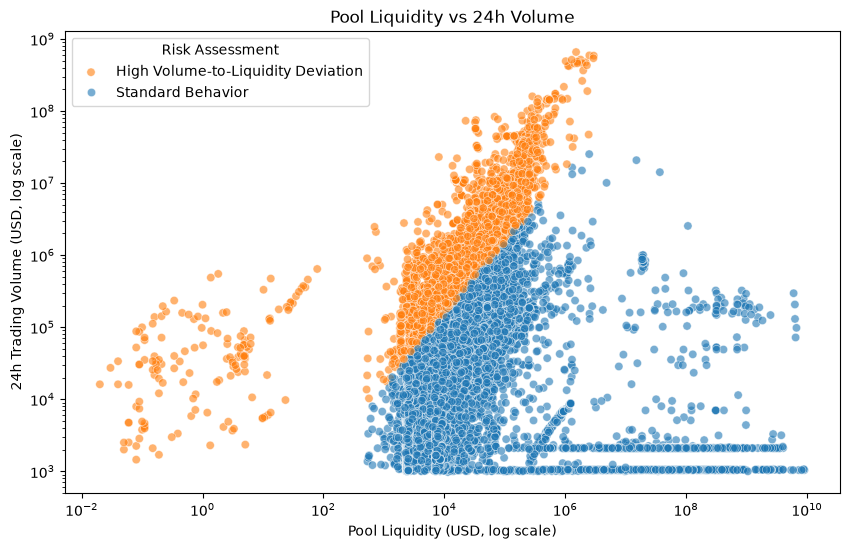

In [16]:
plt.figure(figsize=(10,6))
sns.scatterplot(x='liquidity_usd', y='volume_24h', data=df, hue='flag_high_vol_to_liq', alpha=0.6)
plt.legend(loc=('upper left'), title=('Risk Assessment'), labels=('High Volume-to-Liquidity Deviation', 'Standard Behavior'))
plt.yscale('log')
plt.xscale('log')
plt.title('Pool Liquidity vs 24h Volume')
plt.xlabel('Pool Liquidity (USD, log scale)')
plt.ylabel('24h Trading Volume (USD, log scale)')

Text(0, 0.5, '24h Sells Count (log scale)')

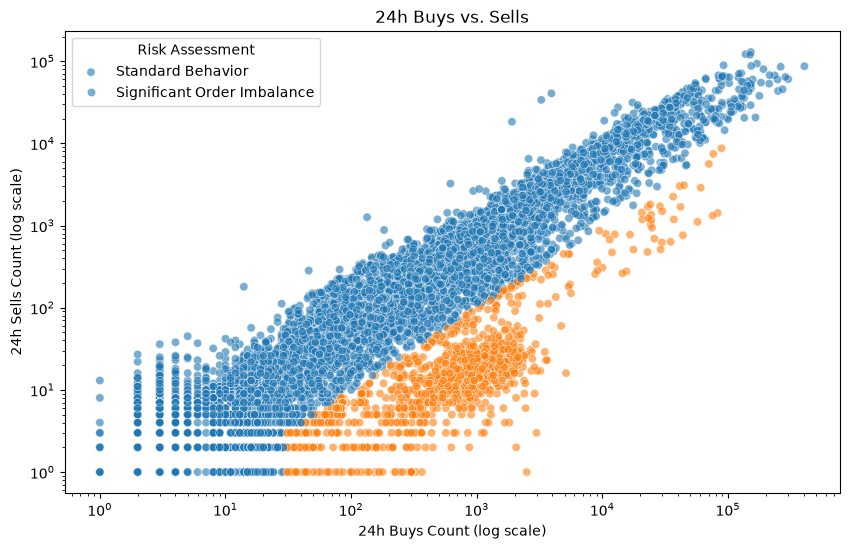

In [17]:
plt.figure(figsize=(10,6))
sns.scatterplot(x='buys_24h', y='sells_24h', data=df, hue='flag_buy_sell_imbalance', alpha=0.6)
plt.xscale('log')
plt.yscale('log')
plt.legend(title=('Risk Assessment'), labels=('Standard Behavior','Significant Order Imbalance'))
plt.title('24h Buys vs. Sells')
plt.xlabel('24h Buys Count (log scale)')
plt.ylabel('24h Sells Count (log scale)')

Text(0.5, 1.0, 'Correlation Matrix')

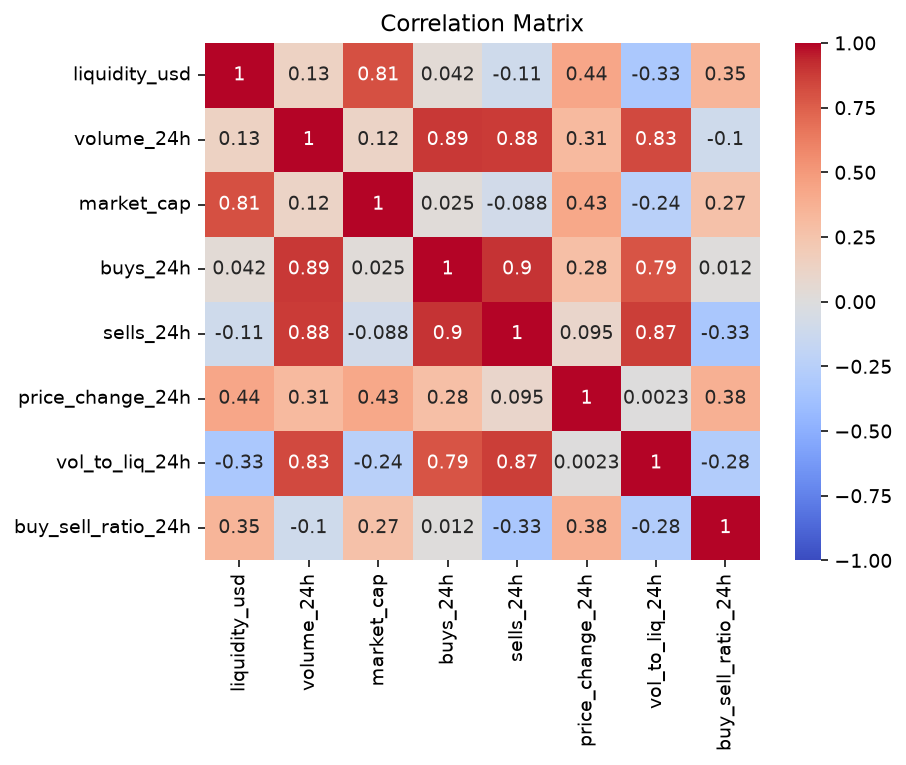

In [18]:
corr_metrics = ['liquidity_usd', 'volume_24h', 'market_cap', 'buys_24h', 'sells_24h', 'price_change_24h', 'vol_to_liq_24h', 'buy_sell_ratio_24h']
corr_matrix = df[corr_metrics].corr(method='spearman')
plt.figure(dpi=140)
sns.heatmap(data=corr_matrix, annot=True, vmin=-1, vmax=1, cmap='coolwarm')
plt.title('Correlation Matrix')


Fazit und nächste Schritte
In diesem Projekt habe ich eine Datenerfassung für Dexscreener-Daten, den Export in CSV, eine erste Datenbereinigung, abgeleitete Kennzahlen sowie explorative Visualisierungen umgesetzt. Zusätzlich markieren heuristische Flags einige auffällige Kombinationen aus Handelsaktivität, Liquidität und Preisänderungen.
Die Ergebnisse sind eine explorative Momentaufnahme des erfassten Datensatzes. Die Regeln wurden nicht gegen bestätigte Betrugsfälle validiert und dürfen daher nicht als zuverlässige Vorhersage von Rugpulls oder anderen Verlustereignissen interpretiert werden. Außerdem kann das Ersetzen fehlender Werte durch null die Analyse beeinflussen.

Mögliche nächste Schritte:
- fehlende Werte je Spalte gezielter behandeln und die Datenbereinigung testen;
- die Auswahl des liquiditätsstärksten Pools dokumentieren und mit anderen Auswahlregeln vergleichen;
- die Schwellenwerte anhand gelabelter historischer Daten evaluieren;
- erst nach ausreichender Datenbasis und Validierung prüfen, ob ein Machine-Learning-Modell einen messbaren Mehrwert bietet.